In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [5]:
resume_df = pd.read_csv("clean_resume_data.csv")
resume_df.head(5)

,Category,Feature,Char_len,word_len,clean_text,Tokenization,Nostopword_Text,Lemmatized_Text
0,HR,hr administrator marketing associate hr admini...,4255,498,hr administrator marketing associate hr admini...,"['hr', 'administrator', 'marketing', 'associat...","['hr', 'administrator', 'marketing', 'associat...",hr administrator market associate hr administr...
1,HR,hr specialist hr operations summary media prof...,4376,529,hr specialist hr operations summary media prof...,"['hr', 'specialist', 'hr', 'operations', 'summ...","['hr', 'specialist', 'hr', 'operations', 'summ...",hr specialist hr operations summary media prof...
2,HR,hr director summary years experience recruitin...,5920,708,hr director summary years experience recruitin...,"['hr', 'director', 'summary', 'years', 'experi...","['hr', 'director', 'summary', 'years', 'experi...",hr director summary years experience recruit p...
3,HR,hr specialist summary dedicated driven dynamic...,2145,258,hr specialist summary dedicated driven dynamic...,"['hr', 'specialist', 'summary', 'dedicated', '...","['hr', 'specialist', 'summary', 'dedicated', '...",hr specialist summary dedicate drive dynamic y...
4,HR,hr manager skill highlights hr skills hr depar...,7281,872,hr manager skill highlights hr skills hr depar...,"['hr', 'manager', 'skill', 'highlights', 'hr',...","['hr', 'manager', 'skill', 'highlights', 'hr',...",hr manager skill highlight hr skills hr depart...


In [6]:
resume_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2483 entries, 0 to 2482
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Category         2483 non-null   str  
 1   Feature          2483 non-null   str  
 2   Char_len         2483 non-null   int64
 3   word_len         2483 non-null   int64
 4   clean_text       2483 non-null   str  
 5   Tokenization     2483 non-null   str  
 6   Nostopword_Text  2483 non-null   str  
 7   Lemmatized_Text  2483 non-null   str  
dtypes: int64(2), str(6)
memory usage: 65.9 MB


In [7]:
resume_df.columns

Index(['Category', 'Feature', 'Char_len', 'word_len', 'clean_text',
       'Tokenization', 'Nostopword_Text', 'Lemmatized_Text'],
      dtype='str')

In [8]:
resume_df.shape

(2483, 8)

In [9]:
resume_df.size

19864

In [10]:
resume_df.isnull().sum()

Category           0
Feature            0
Char_len           0
word_len           0
clean_text         0
Tokenization       0
Nostopword_Text    0
Lemmatized_Text    0
dtype: int64

In [11]:
resume_df.duplicated().sum()

2

In [12]:
resume_df.duplicated(subset=["Feature"]).sum()

2

In [13]:
resume_df.isnull().sum()

Category           0
Feature            0
Char_len           0
word_len           0
clean_text         0
Tokenization       0
Nostopword_Text    0
Lemmatized_Text    0
dtype: int64

In [ ]:
# resume_df.drop(columns = ["ID"],inplace = True)

In [15]:
resume_df.drop_duplicates()

,Category,Feature,Char_len,word_len,clean_text,Tokenization,Nostopword_Text,Lemmatized_Text
0,HR,hr administrator marketing associate hr admini...,4255,498,hr administrator marketing associate hr admini...,"['hr', 'administrator', 'marketing', 'associat...","['hr', 'administrator', 'marketing', 'associat...",hr administrator market associate hr administr...
1,HR,hr specialist hr operations summary media prof...,4376,529,hr specialist hr operations summary media prof...,"['hr', 'specialist', 'hr', 'operations', 'summ...","['hr', 'specialist', 'hr', 'operations', 'summ...",hr specialist hr operations summary media prof...
2,HR,hr director summary years experience recruitin...,5920,708,hr director summary years experience recruitin...,"['hr', 'director', 'summary', 'years', 'experi...","['hr', 'director', 'summary', 'years', 'experi...",hr director summary years experience recruit p...
3,HR,hr specialist summary dedicated driven dynamic...,2145,258,hr specialist summary dedicated driven dynamic...,"['hr', 'specialist', 'summary', 'dedicated', '...","['hr', 'specialist', 'summary', 'dedicated', '...",hr specialist summary dedicate drive dynamic y...
4,HR,hr manager skill highlights hr skills hr depar...,7281,872,hr manager skill highlights hr skills hr depar...,"['hr', 'manager', 'skill', 'highlights', 'hr',...","['hr', 'manager', 'skill', 'highlights', 'hr',...",hr manager skill highlight hr skills hr depart...
...,...,...,...,...,...,...,...,...
2477,AVIATION,advanced level wheeled vehicle mechanic career...,6327,767,advanced level wheeled vehicle mechanic career...,"['advanced', 'level', 'wheeled', 'vehicle', 'm...","['advanced', 'level', 'wheeled', 'vehicle', 'm...",advance level wheel vehicle mechanic career fo...
2478,AVIATION,rank sgt e non commissioned officer charge bri...,3978,494,rank sgt e non commissioned officer charge bri...,"['rank', 'sgt', 'e', 'non', 'commissioned', 'o...","['rank', 'sgt', 'e', 'non', 'commissioned', 'o...",rank sgt e non commission officer charge briga...
2479,AVIATION,government relations communications organizati...,5624,647,government relations communications organizati...,"['government', 'relations', 'communications', ...","['government', 'relations', 'communications', ...",government relations communications organizati...
2480,AVIATION,geek squad agent professional profile support ...,1533,180,geek squad agent professional profile support ...,"['geek', 'squad', 'agent', 'professional', 'pr...","['geek', 'squad', 'agent', 'professional', 'pr...",geek squad agent professional profile support ...


In [16]:
resume_df.dropna()

,Category,Feature,Char_len,word_len,clean_text,Tokenization,Nostopword_Text,Lemmatized_Text
0,HR,hr administrator marketing associate hr admini...,4255,498,hr administrator marketing associate hr admini...,"['hr', 'administrator', 'marketing', 'associat...","['hr', 'administrator', 'marketing', 'associat...",hr administrator market associate hr administr...
1,HR,hr specialist hr operations summary media prof...,4376,529,hr specialist hr operations summary media prof...,"['hr', 'specialist', 'hr', 'operations', 'summ...","['hr', 'specialist', 'hr', 'operations', 'summ...",hr specialist hr operations summary media prof...
2,HR,hr director summary years experience recruitin...,5920,708,hr director summary years experience recruitin...,"['hr', 'director', 'summary', 'years', 'experi...","['hr', 'director', 'summary', 'years', 'experi...",hr director summary years experience recruit p...
3,HR,hr specialist summary dedicated driven dynamic...,2145,258,hr specialist summary dedicated driven dynamic...,"['hr', 'specialist', 'summary', 'dedicated', '...","['hr', 'specialist', 'summary', 'dedicated', '...",hr specialist summary dedicate drive dynamic y...
4,HR,hr manager skill highlights hr skills hr depar...,7281,872,hr manager skill highlights hr skills hr depar...,"['hr', 'manager', 'skill', 'highlights', 'hr',...","['hr', 'manager', 'skill', 'highlights', 'hr',...",hr manager skill highlight hr skills hr depart...
...,...,...,...,...,...,...,...,...
2478,AVIATION,rank sgt e non commissioned officer charge bri...,3978,494,rank sgt e non commissioned officer charge bri...,"['rank', 'sgt', 'e', 'non', 'commissioned', 'o...","['rank', 'sgt', 'e', 'non', 'commissioned', 'o...",rank sgt e non commission officer charge briga...
2479,AVIATION,government relations communications organizati...,5624,647,government relations communications organizati...,"['government', 'relations', 'communications', ...","['government', 'relations', 'communications', ...",government relations communications organizati...
2480,AVIATION,geek squad agent professional profile support ...,1533,180,geek squad agent professional profile support ...,"['geek', 'squad', 'agent', 'professional', 'pr...","['geek', 'squad', 'agent', 'professional', 'pr...",geek squad agent professional profile support ...
2481,AVIATION,program director office manager summary highly...,4039,514,program director office manager summary highly...,"['program', 'director', 'office', 'manager', '...","['program', 'director', 'office', 'manager', '...",program director office manager summary highly...


In [17]:
resume_df["Category"].value_counts()

Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      119
ADVOCATE                  118
CHEF                      118
FINANCE                   118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
AVIATION                  117
SALES                     116
HEALTHCARE                115
CONSULTANT                115
BANKING                   115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64

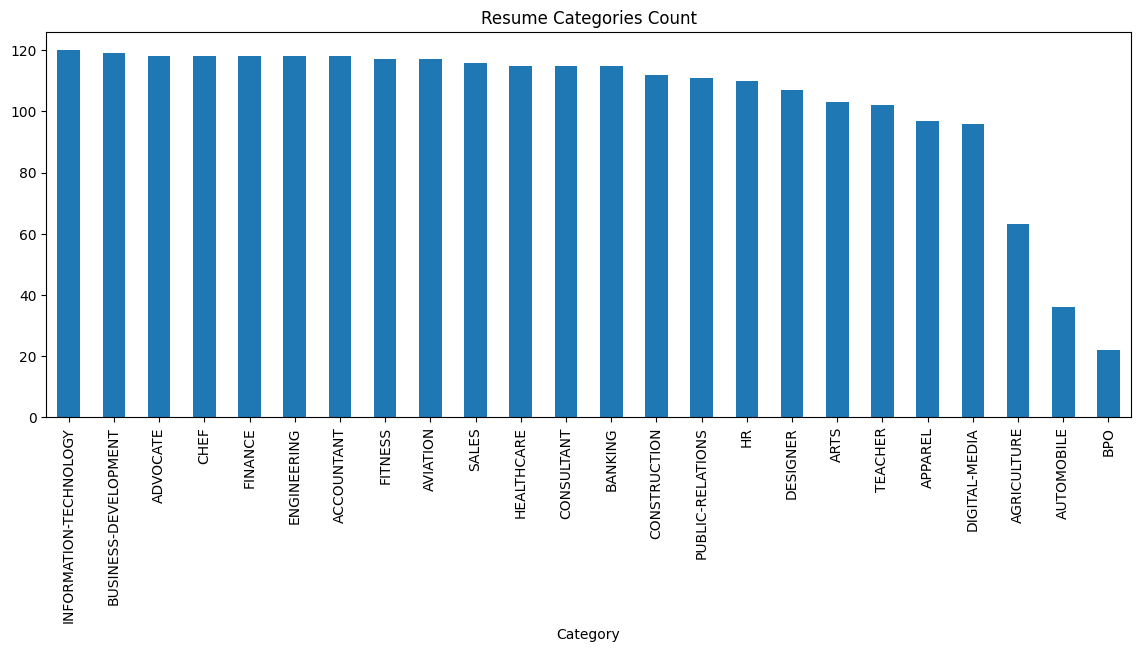

In [18]:
resume_df["Category"].value_counts().plot(kind="bar",figsize = (14,5))
plt.xticks(rotation=90)
plt.title("Resume Categories Count")
plt.show()

In [19]:
# feature engineering
resume_df["Char_len"] = resume_df["Feature"].astype(str).apply(len)

resume_df["word_len"] = resume_df["Feature"].astype(str).apply(lambda x: len(x.split()))

print(resume_df["word_len"].describe())
# df.describe()


count    2483.000000
mean      587.250906
std       257.390903
min        77.000000
25%       477.500000
50%       549.000000
75%       677.500000
max      3565.000000
Name: word_len, dtype: float64


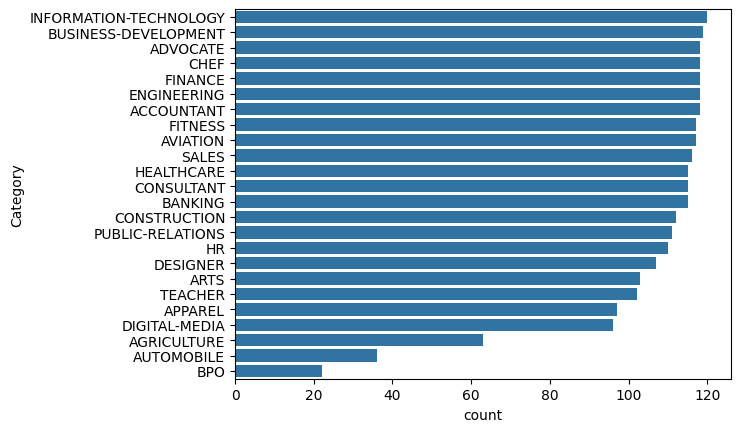

In [20]:
sns.countplot(y="Category", data=resume_df, order=resume_df["Category"].value_counts().index)
plt.show()

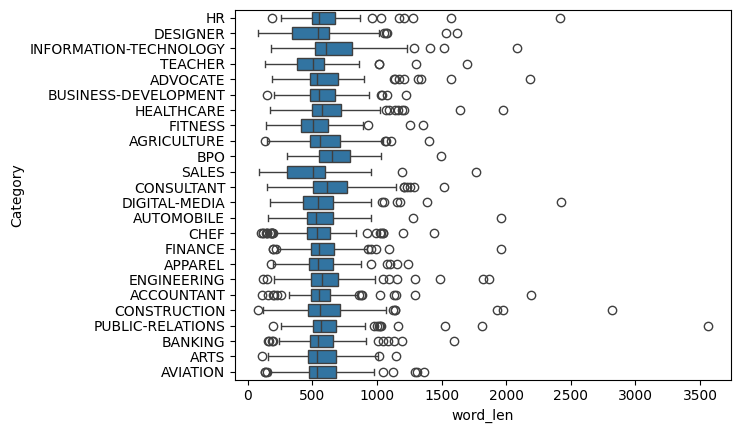

In [21]:
sns.boxplot(x="word_len", y="Category", data=resume_df)
plt.show()

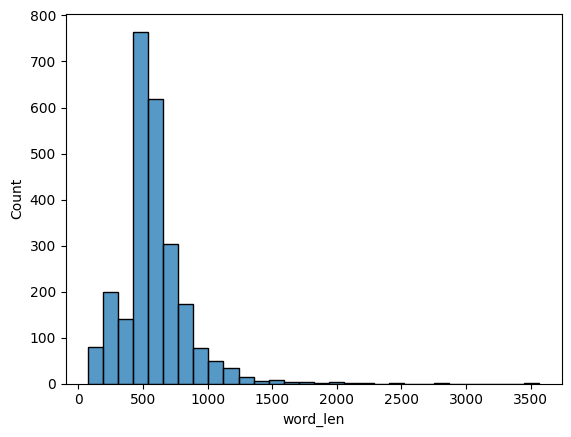

In [22]:
sns.histplot(resume_df["word_len"], bins=30)
plt.show()

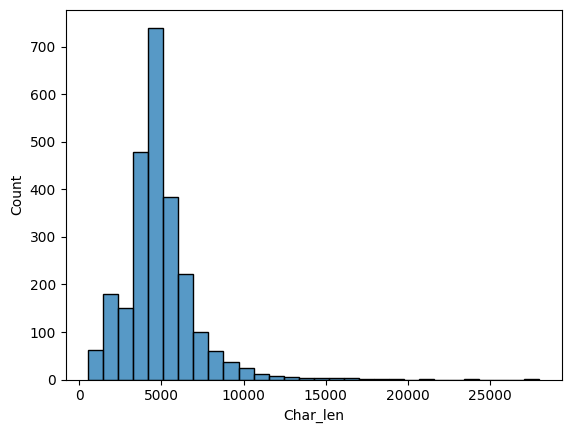

In [23]:
sns.histplot(resume_df["Char_len"], bins=30)
plt.show()

In [24]:
resume_df.sort_values("word_len")[["Category","Feature","word_len"]].head(10)

,Category,Feature,word_len
1930,CONSTRUCTION,construction worker highlights highly motivate...,77
130,DESIGNER,graphic designer experience graphic designer j...,80
1048,SALES,sales associate summary motivated sales associ...,87
1101,SALES,sales associate summary goal become associated...,90
1038,SALES,sales associate experience current sales assoc...,103
1399,CHEF,sushi chef executive years experience high end...,105
153,DESIGNER,floral designer skills billings cash handling ...,106
1851,ACCOUNTANT,accountant summary accountant medium sized com...,109
2321,ARTS,certified custom framer qualifications ability...,111
2032,CONSTRUCTION,physical therapist technician education glenco...,120


In [25]:
print((resume_df["Feature"].astype(str).str.lower() == "nan").sum())

0


In [26]:
resume_df = resume_df.dropna(subset=["Feature"]).reset_index(drop=True)

In [27]:
import re
def clean_resume(text):
    text = str(text).lower()

    # remove urls
    text = re.sub(r"http\S+|www\S+", " ", text)

    # remove emails
    text = re.sub(r"\S+@\S+", " ", text)

    # remove phone number
    text = re.sub(r"\+?\d[\d -]{8,}\d", " ", text)

    #  # keep alphabets + important tech symbols
    text = re.sub(r"[^a-zA-Z+#. ]", " ", text)

    return text

In [28]:
resume_df["clean_text"]=resume_df["Feature"].apply(clean_resume)

In [29]:
resume_df["clean_text"]

0       hr administrator marketing associate hr admini...
1       hr specialist hr operations summary media prof...
2       hr director summary years experience recruitin...
3       hr specialist summary dedicated driven dynamic...
4       hr manager skill highlights hr skills hr depar...
                              ...                        
2478    rank sgt e non commissioned officer charge bri...
2479    government relations communications organizati...
2480    geek squad agent professional profile support ...
2481    program director office manager summary highly...
2482    storekeeper ii professional summary purpose do...
Name: clean_text, Length: 2483, dtype: str

In [31]:
from nltk.corpus import stopwords

In [32]:
resume_df["Tokenization"]=resume_df.apply(lambda row:nltk.word_tokenize(row["clean_text"]),axis=1)
print(*resume_df["Tokenization"][:5],sep="\n")

['hr', 'administrator', 'marketing', 'associate', 'hr', 'administrator', 'summary', 'dedicated', 'customer', 'service', 'manager', 'years', 'experience', 'hospitality', 'customer', 'service', 'management', 'respected', 'builder', 'leader', 'customer', 'focused', 'teams', 'strives', 'instill', 'shared', 'enthusiastic', 'commitment', 'customer', 'service', 'highlights', 'focused', 'customer', 'satisfaction', 'team', 'management', 'marketing', 'savvy', 'conflict', 'resolution', 'techniques', 'training', 'development', 'skilled', 'multi', 'tasker', 'client', 'relations', 'specialist', 'accomplishments', 'missouri', 'dot', 'supervisor', 'training', 'certification', 'certified', 'ihg', 'customer', 'loyalty', 'marketing', 'segment', 'hilton', 'general', 'manager', 'training', 'certification', 'accomplished', 'trainer', 'cross', 'server', 'hospitality', 'systems', 'hilton', 'onq', 'micros', 'opera', 'pms', 'fidelio', 'opera', 'reservation', 'system', 'ors', 'holidex', 'completed', 'courses', '

In [33]:
from string import punctuation
def remove_stopword(text):
    stop_word = (stopwords.words("english"))
    stop = stop_word+list(punctuation)
    filtered_text = [word for word in text if word not in stop]
    return filtered_text

resume_df["Nostopword_Text"]=resume_df["Tokenization"].apply(remove_stopword)
print(*resume_df["Nostopword_Text"][:5] ,sep ="\n")

['hr', 'administrator', 'marketing', 'associate', 'hr', 'administrator', 'summary', 'dedicated', 'customer', 'service', 'manager', 'years', 'experience', 'hospitality', 'customer', 'service', 'management', 'respected', 'builder', 'leader', 'customer', 'focused', 'teams', 'strives', 'instill', 'shared', 'enthusiastic', 'commitment', 'customer', 'service', 'highlights', 'focused', 'customer', 'satisfaction', 'team', 'management', 'marketing', 'savvy', 'conflict', 'resolution', 'techniques', 'training', 'development', 'skilled', 'multi', 'tasker', 'client', 'relations', 'specialist', 'accomplishments', 'missouri', 'dot', 'supervisor', 'training', 'certification', 'certified', 'ihg', 'customer', 'loyalty', 'marketing', 'segment', 'hilton', 'general', 'manager', 'training', 'certification', 'accomplished', 'trainer', 'cross', 'server', 'hospitality', 'systems', 'hilton', 'onq', 'micros', 'opera', 'pms', 'fidelio', 'opera', 'reservation', 'system', 'ors', 'holidex', 'completed', 'courses', '

In [34]:
from nltk.stem import WordNetLemmatizer

In [35]:
lemmatizer = WordNetLemmatizer()

def lemmatize_word(text):
    lemmas = [lemmatizer.lemmatize(word,pos ="v") for word in text]
    return lemmas

resume_df["Lemmatized_Text"] = resume_df["Nostopword_Text"].apply(lemmatize_word)


print(*resume_df["Lemmatized_Text"][:5] ,sep ="\n")

['hr', 'administrator', 'market', 'associate', 'hr', 'administrator', 'summary', 'dedicate', 'customer', 'service', 'manager', 'years', 'experience', 'hospitality', 'customer', 'service', 'management', 'respect', 'builder', 'leader', 'customer', 'focus', 'team', 'strive', 'instill', 'share', 'enthusiastic', 'commitment', 'customer', 'service', 'highlight', 'focus', 'customer', 'satisfaction', 'team', 'management', 'market', 'savvy', 'conflict', 'resolution', 'techniques', 'train', 'development', 'skilled', 'multi', 'tasker', 'client', 'relations', 'specialist', 'accomplishments', 'missouri', 'dot', 'supervisor', 'train', 'certification', 'certify', 'ihg', 'customer', 'loyalty', 'market', 'segment', 'hilton', 'general', 'manager', 'train', 'certification', 'accomplish', 'trainer', 'cross', 'server', 'hospitality', 'systems', 'hilton', 'onq', 'micros', 'opera', 'pms', 'fidelio', 'opera', 'reservation', 'system', 'ors', 'holidex', 'complete', 'course', 'seminars', 'customer', 'service', '

In [36]:
resume_df["Lemmatized_Text"] = resume_df["Lemmatized_Text"].apply(lambda x: " ".join(x))

In [37]:
print(resume_df.columns)

Index(['Category', 'Feature', 'Char_len', 'word_len', 'clean_text',
       'Tokenization', 'Nostopword_Text', 'Lemmatized_Text'],
      dtype='str')


In [38]:
resume_df.to_csv("clean_resume_data.csv", index=False)